In [ ]:
from pathlib import Path
import pandas as pd

# This path works when the notebook is inside the project's notebooks folder.
data_folder = Path('../data/raw')

print('Looking for files in:', data_folder.resolve())
print('Folder exists:', data_folder.exists())

Looking for files in: /Users/abhimark/Documents/Codex/2026-11-14/gi/data/raw
Folder exists: True


## Loading the files

In [2]:
orders = pd.read_csv(data_folder / 'orders.csv')
prior_products = pd.read_csv(data_folder / 'order_products__prior.csv')
products = pd.read_csv(data_folder / 'products.csv')

print('Orders:', orders.shape)
print('Prior order products:', prior_products.shape)
print('Products:', products.shape)

Orders: (3421083, 7)
Prior order products: (32434489, 4)
Products: (49688, 4)


In [3]:
orders.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [4]:
prior_products.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


In [5]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


## Checking blank values

In [8]:
print('Orders')
print(orders.isna().sum(),'\n')

print('Prior order products')
print(prior_products.isna().sum(),'\n')

print('Products')
print(products.isna().sum())

Orders
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64 

Prior order products
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64 

Products
product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64


## Check duplicate IDs

In [9]:
print('Repeated order IDs:', orders['order_id'].duplicated().sum())
print('Repeated product IDs:', products['product_id'].duplicated().sum())
print(
    'Repeated order-product pairs:',
    prior_products.duplicated(subset=['order_id', 'product_id']).sum()
)

Repeated order IDs: 0
Repeated product IDs: 0
Repeated order-product pairs: 0


## Confirm the tables connect

In [10]:
unknown_orders = ~prior_products['order_id'].isin(orders['order_id'])
unknown_products = ~prior_products['product_id'].isin(products['product_id'])

print('Prior rows with an unknown order:', unknown_orders.sum())
print('Prior rows with an unknown product:', unknown_products.sum())

Prior rows with an unknown order: 0
Prior rows with an unknown product: 0


## Audit result

Our audit found no duplicate keys and no broken links between the three files. The only blanks are `days_since_prior_order` values in `orders`; those are expected for a customer's first order.

## Find products customers reorder

The reorder rate is the share of product-order rows marked as a reorder. We use a minimum of 1,000 product-order rows so that products with very few purchases do not rank highly by chance. This is a repeat-demand signal, not a stockout prediction.

In [11]:
product_summary = prior_products.groupby('product_id').agg(
    times_ordered=('order_id', 'count'),
    reorder_count=('reordered', 'sum')
).reset_index()

product_summary['reorder_rate_pct'] = (
    product_summary['reorder_count'] / product_summary['times_ordered'] * 100
)

product_summary = product_summary.merge(
    products[['product_id', 'product_name']], on='product_id'
)
common_products = product_summary[product_summary['times_ordered'] >= 1000]

top_reorder_rate = common_products.sort_values(
    'reorder_rate_pct', ascending=False
).head(10)
top_reorder_rate[['product_name', 'times_ordered', 'reorder_rate_pct']]

,product_name,times_ordered,reorder_rate_pct
9288,Half And Half Ultra Pasteurized,2921,86.169120
45495,Whole Organic Omega 3 Milk,9108,86.023276
43386,Organic Lactose Free Whole Milk,8477,85.903032
5511,Organic Homogenized Whole Milk,3970,85.768262
47220,Ultra-Purified Water,1489,85.762257
29441,"Milk, Organic, Vitamin D",20198,85.434201
38681,Organic Reduced Fat Milk,35663,85.068558
34191,Goat Milk,5185,84.995178
24848,Banana,472565,84.350089
31714,Organic Whole Milk,9842,84.119081


## Compare with the most ordered products

A product can have a high reorder rate without being one of the most ordered overall. This table compares absolute order volume and repeat rate.

In [16]:
top_volume = common_products.sort_values(
    'times_ordered', ascending=False
).head(10).copy()

top_volume[['product_name', 'times_ordered', 'reorder_rate_pct']]

,product_name,times_ordered,reorder_rate_pct
24848,Banana,472565,84.350089
13172,Bag of Organic Bananas,379450,83.255501
21133,Organic Strawberries,264683,77.770389
21899,Organic Baby Spinach,241921,77.250011
47198,Organic Hass Avocado,213584,79.655311
47755,Organic Avocado,176815,75.810310
47615,Large Lemon,152657,69.603752
16793,Strawberries,142951,69.815531
26204,Limes,140627,68.100720
27839,Organic Whole Milk,137905,83.035423


**finding the busiest ordering hours**

<Axes: title={'center': 'Instacart Orders by Hour'}, xlabel='Hour of day', ylabel='Number of orders'>

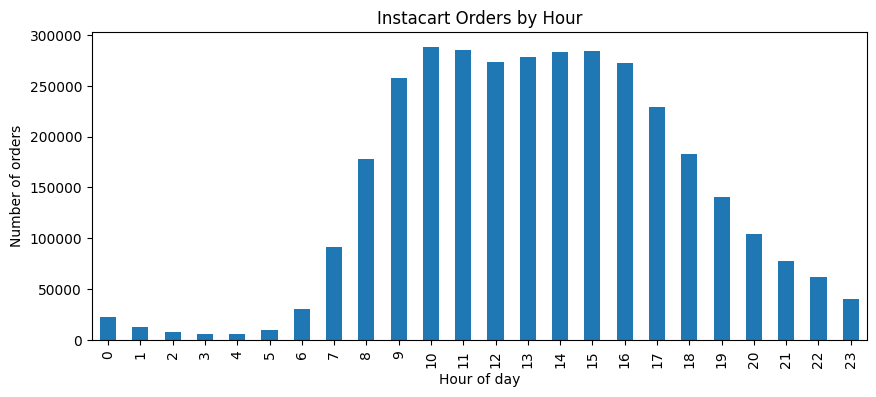

In [17]:
orders_by_hour = orders.groupby("order_hour_of_day").size()
orders_by_hour = orders_by_hour.sort_index()

orders_by_hour.plot(
    kind="bar",
    figsize=(10, 4),
    title="Instacart Orders by Hour",
    xlabel="Hour of day",
    ylabel="Number of orders"
)

**comparing orders by day code**

<Axes: title={'center': 'Instacart Orders by Day Code'}, xlabel='Day code (0–6)', ylabel='Number of orders'>

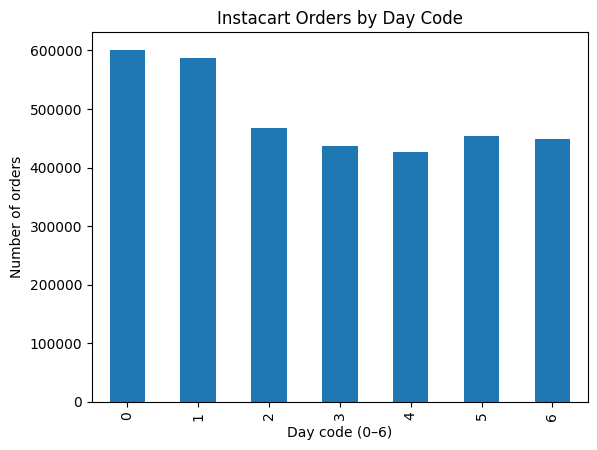

In [18]:
orders_by_day = (
    orders.groupby("order_dow")
    .size()
    .reset_index(name="order_count")
    .sort_values("order_dow")
)

orders_by_day.plot(
    kind="bar",
    x="order_dow",
    y="order_count",
    title="Instacart Orders by Day Code",
    xlabel="Day code (0–6)",
    ylabel="Number of orders",
    legend=False
)

**creating a product monitoring shortlist**

In [20]:
volume_cutoff = common_products["times_ordered"].quantile(0.75)
reorder_cutoff = common_products["reorder_rate_pct"].quantile(0.75)

watchlist = common_products[
    (common_products["times_ordered"] >= volume_cutoff)
    & (common_products["reorder_rate_pct"] >= reorder_cutoff)
]

watchlist = watchlist.sort_values(
    "times_ordered",
    ascending=False
)

watchlist[[
    "product_name",
    "times_ordered",
    "reorder_rate_pct"
]].head(10)

,product_name,times_ordered,reorder_rate_pct
24848,Banana,472565,84.350089
13172,Bag of Organic Bananas,379450,83.255501
21133,Organic Strawberries,264683,77.770389
21899,Organic Baby Spinach,241921,77.250011
47198,Organic Hass Avocado,213584,79.655311
47755,Organic Avocado,176815,75.810310
47615,Large Lemon,152657,69.603752
16793,Strawberries,142951,69.815531
26204,Limes,140627,68.100720
27839,Organic Whole Milk,137905,83.035423


**Preparing basket sizes**

In [21]:
basket_sizes = (
    prior_products.groupby("order_id")
    .size()
    .reset_index(name="product_lines")
)

order_times = orders[
    ["order_id", "order_hour_of_day", "order_dow"]
]

orders_with_baskets = order_times.merge(
    basket_sizes,
    on="order_id",
    how="inner"
)

In [23]:
import matplotlib.pyplot as plt

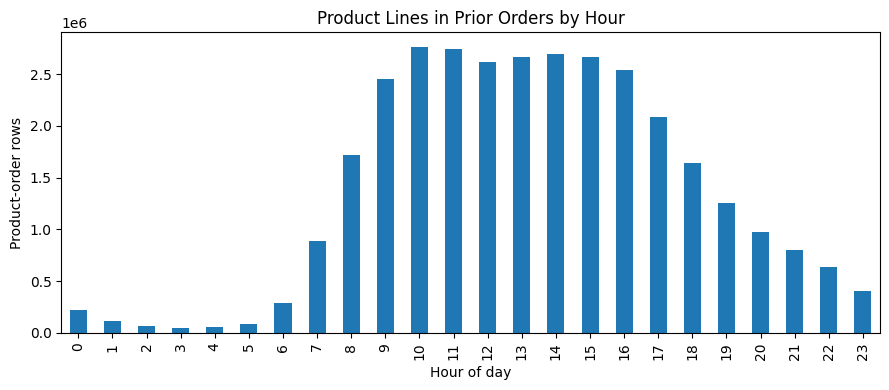

In [ ]:
by_hour = (
    orders_with_baskets.groupby("order_hour_of_day")
    .agg(
        order_count=("order_id", "count"),
        total_product_lines=("product_lines", "sum"),
        avg_product_lines=("product_lines", "mean"),
        median_product_lines=("product_lines", "median")
    )
    .reset_index()
    .sort_values("order_hour_of_day")
)

by_hour["avg_product_lines"] = by_hour["avg_product_lines"].round(2)

by_hour.plot(
    kind="bar",
    x="order_hour_of_day",
    y="total_product_lines",
    legend=False,
    title="Product Lines in Prior Orders by Hour",
    xlabel="Hour of day",
    ylabel="Product-order rows",
    figsize=(9, 4)
)
plt.tight_layout()
plt.show()

**Product lines and basket size by hour**

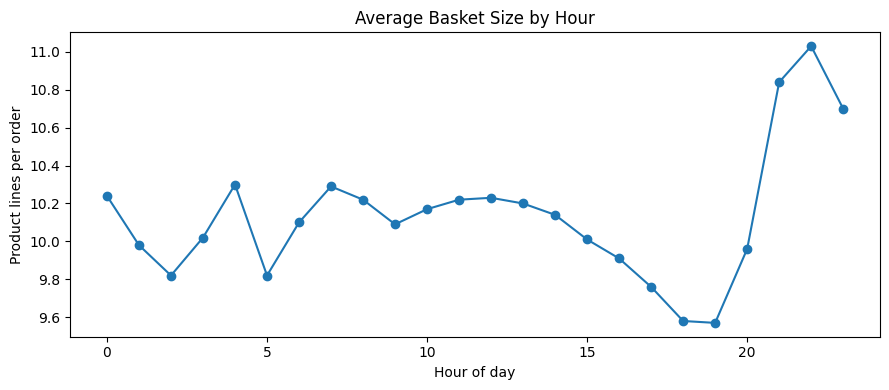

In [26]:
by_hour.plot(
    kind="line",
    x="order_hour_of_day",
    y="avg_product_lines",
    marker="o",
    legend=False,
    title="Average Basket Size by Hour",
    xlabel="Hour of day",
    ylabel="Product lines per order",
    figsize=(9, 4)
)
plt.tight_layout()
plt.show()

**Product demand by day code and hour**

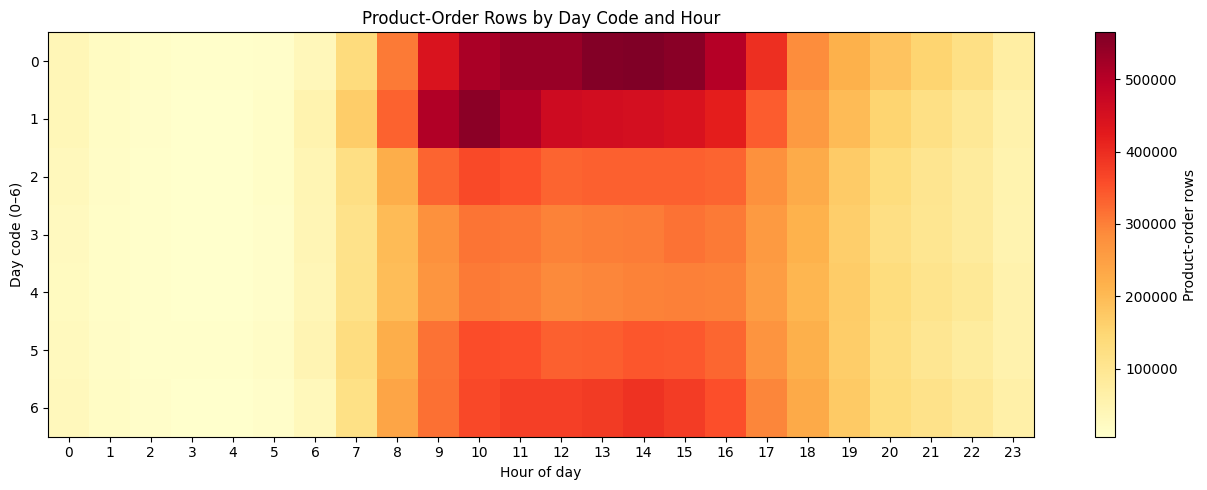

In [ ]:
by_window = (
    orders_with_baskets.groupby(["order_dow", "order_hour_of_day"])
    .agg(
        order_count=("order_id", "count"),
        product_order_rows=("product_lines", "sum")
    )
    .reset_index()
)


heatmap_data = by_window.pivot(
    index="order_dow",
    columns="order_hour_of_day",
    values="product_order_rows"
)

plt.figure(figsize=(13, 5))
plt.imshow(heatmap_data, aspect="auto", cmap="YlOrRd")
plt.colorbar(label="Product-order rows")
plt.title("Product-Order Rows by Day Code and Hour")
plt.xlabel("Hour of day")
plt.ylabel("Day code (0–6)")
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.tight_layout()
plt.show()

**Time between customer orders**

In [28]:
intervals = orders["days_since_prior_order"].dropna()

time_bands = pd.cut(
    intervals,
    bins=[-1, 7, 14, 21, 30],
    labels=["0–7 days", "8–14 days", "15–21 days", "22–30 days"]
)

summary = (
    time_bands.value_counts(sort=False)
    .rename_axis("days_between_orders")
    .reset_index(name="number_of_intervals")
)

summary["share_percent"] = (
    summary["number_of_intervals"] / summary["number_of_intervals"].sum() * 100
).round(1)

summary

,days_between_orders,number_of_intervals,share_percent
0,0–7 days,1620033,50.4
1,8–14 days,735651,22.9
2,15–21 days,307027,9.6
3,22–30 days,552163,17.2


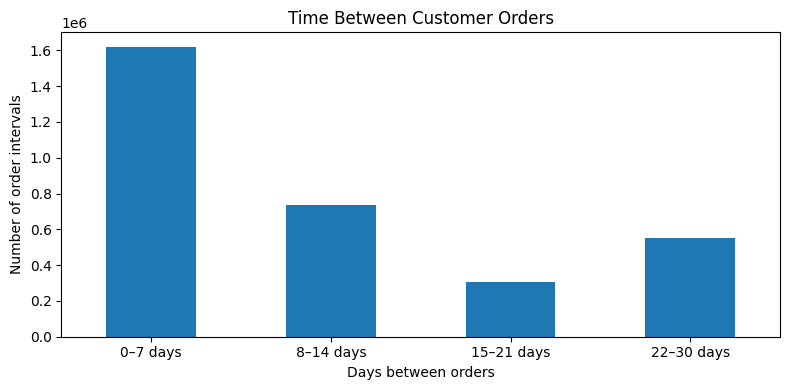

In [29]:
summary.plot(
    kind="bar",
    x="days_between_orders",
    y="number_of_intervals",
    legend=False,
    title="Time Between Customer Orders",
    xlabel="Days between orders",
    ylabel="Number of order intervals",
    figsize=(8, 4)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Category files**

In [30]:
aisles = pd.read_csv(data_folder / "aisles.csv")
departments = pd.read_csv(data_folder / "departments.csv")

In [37]:
aisles.shape

(134, 2)

In [38]:
departments.shape

(21, 2)

In [33]:
aisles.head()

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [36]:
departments.head()

,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


**Count orders and reorders for each product**

In [39]:
product_summary = (
    prior_products.groupby("product_id")
    .agg(
        product_order_rows=("reordered", "size"),
        reorder_count=("reordered", "sum")
    )
    .reset_index()
)

product_summary = product_summary.merge(
    products[["product_id", "aisle_id", "department_id"]],
    on="product_id"
)

**Summarize by department**

In [40]:
department_summary = (
    product_summary
    .merge(departments, on="department_id")
    .groupby(["department_id", "department"])
    .agg(
        product_order_rows=("product_order_rows", "sum"),
        products=("product_id", "nunique"),
        reorder_count=("reorder_count", "sum")
    )
    .reset_index()
)

department_summary["reorder_rate_pct"] = (
    department_summary["reorder_count"]
    / department_summary["product_order_rows"]
    * 100
).round(1)

department_summary.sort_values(
    "product_order_rows",
    ascending=False
).head(10)

,department_id,department,product_order_rows,products,reorder_count,reorder_rate_pct
3,4,produce,9479291,1684,6160710,65.0
15,16,dairy eggs,5414016,3448,3627221,67.0
18,19,snacks,2887550,6263,1657973,57.4
6,7,beverages,2690129,4363,1757892,65.3
0,1,frozen,2236432,4007,1211890,54.2
12,13,pantry,1875577,5370,650301,34.7
2,3,bakery,1176787,1516,739188,62.8
14,15,canned goods,1068058,2092,488535,45.7
19,20,deli,1051249,1322,638864,60.8
8,9,dry goods pasta,866627,1858,399581,46.1


**Summarize by aisle**

In [41]:
aisle_summary = (
    product_summary
    .merge(aisles, on="aisle_id")
    .groupby(["aisle_id", "aisle"])
    .agg(
        product_order_rows=("product_order_rows", "sum"),
        products=("product_id", "nunique"),
        reorder_count=("reorder_count", "sum")
    )
    .reset_index()
)

aisle_summary["reorder_rate_pct"] = (
    aisle_summary["reorder_count"]
    / aisle_summary["product_order_rows"]
    * 100
).round(1)

aisle_summary.sort_values(
    "product_order_rows",
    ascending=False
).head(10)

,aisle_id,aisle,product_order_rows,products,reorder_count,reorder_rate_pct
23,24,fresh fruits,3642188,382,2615469,71.8
82,83,fresh vegetables,3418021,569,2032172,59.5
122,123,packaged vegetables fruits,1765313,615,1127177,63.9
119,120,yogurt,1452343,1026,997018,68.6
20,21,packaged cheese,979763,890,573383,58.5
83,84,milk,891015,243,696264,78.1
114,115,water seltzer sparkling water,841533,344,613977,73.0
106,107,chips pretzels,722470,989,425387,58.9
90,91,soy lactosefree,638253,293,442023,69.3
111,112,bread,584834,557,391937,67.0


**Product-order volume by department**

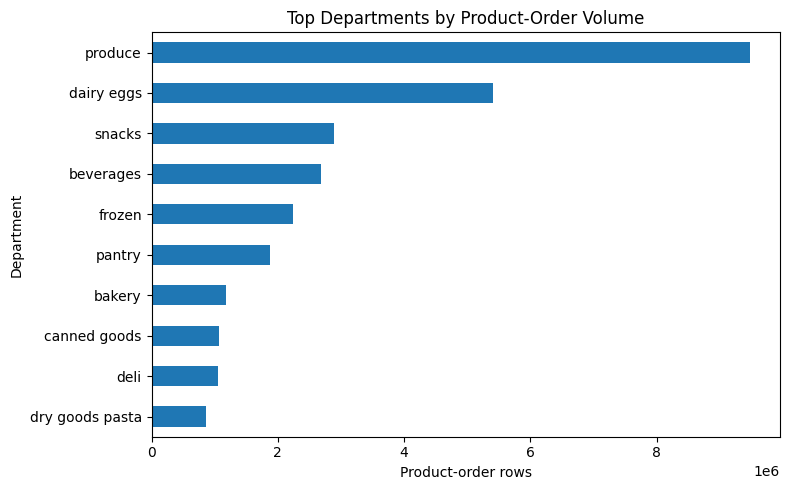

In [42]:
top_departments = department_summary.sort_values(
    "product_order_rows"
).tail(10)

top_departments.plot(
    kind="barh",
    x="department",
    y="product_order_rows",
    legend=False,
    title="Top Departments by Product-Order Volume",
    xlabel="Product-order rows",
    ylabel="Department",
    figsize=(8, 5)
)

plt.tight_layout()
plt.show()

**Reorder rate by department**

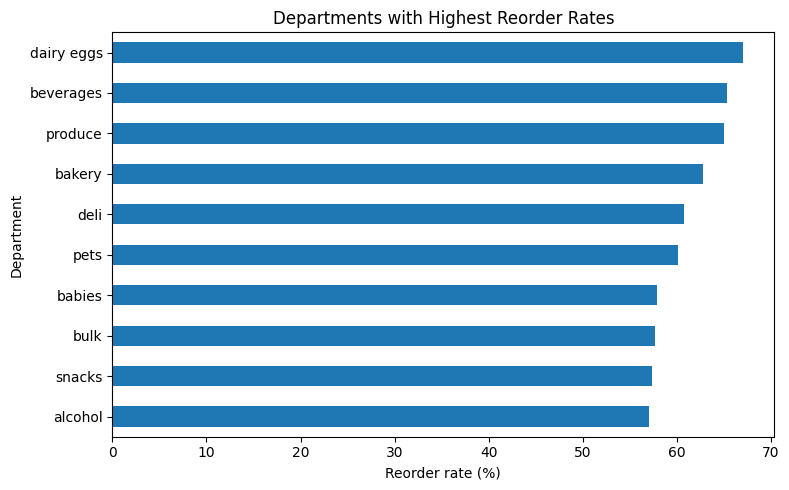

In [43]:
top_reorder_departments = department_summary.sort_values(
    "reorder_rate_pct"
).tail(10)

top_reorder_departments.plot(
    kind="barh",
    x="department",
    y="reorder_rate_pct",
    legend=False,
    title="Departments with Highest Reorder Rates",
    xlabel="Reorder rate (%)",
    ylabel="Department",
    figsize=(8, 5)
)

plt.tight_layout()
plt.show()

**Select the 20 most ordered products**

In [46]:
top_product_ids = prior_products["product_id"].value_counts().head(20).index

popular_items = prior_products[
    prior_products["product_id"].isin(top_product_ids)
][["order_id", "product_id"]]

total_orders = prior_products["order_id"].nunique()

product_order_counts = (
    popular_items.groupby("product_id")["order_id"].nunique()
)

**Find pairs in the same basket**

In [48]:
pairs = popular_items.merge(popular_items, on="order_id")

pairs = pairs[
    pairs["product_id_x"] < pairs["product_id_y"]
]

pair_counts = (
    pairs.groupby(["product_id_x", "product_id_y"])
    .size()
    .reset_index(name="orders_together")
)

**Calculate lift and add product names**

In [51]:
pair_counts["product_a_orders"] = (
    pair_counts["product_id_x"].map(product_order_counts)
)

pair_counts["product_b_orders"] = (
    pair_counts["product_id_y"].map(product_order_counts)
)

pair_counts["lift"] = (
    pair_counts["orders_together"] * total_orders
    / (pair_counts["product_a_orders"] * pair_counts["product_b_orders"])
).round(2)

product_names = products.set_index("product_id")["product_name"]

pair_counts["product_a"] = pair_counts["product_id_x"].map(product_names)
pair_counts["product_b"] = pair_counts["product_id_y"].map(product_names)

In [53]:
pair_counts.sort_values(
    "orders_together",
    ascending=False
)[["product_a", "product_b", "orders_together", "lift"]].head(10)

,product_a,product_b,orders_together,lift
50,Bag of Organic Bananas,Organic Hass Avocado,62341,2.47
38,Bag of Organic Bananas,Organic Strawberries,61628,1.97
72,Organic Strawberries,Banana,56156,1.44
122,Banana,Organic Avocado,53395,2.05
86,Organic Baby Spinach,Banana,51395,1.45
39,Bag of Organic Bananas,Organic Baby Spinach,50372,1.76
57,Strawberries,Banana,41232,1.96
121,Banana,Large Lemon,40880,1.82
81,Organic Strawberries,Organic Hass Avocado,40794,2.32
45,Bag of Organic Bananas,Organic Raspberries,40503,2.50


Most common pairs

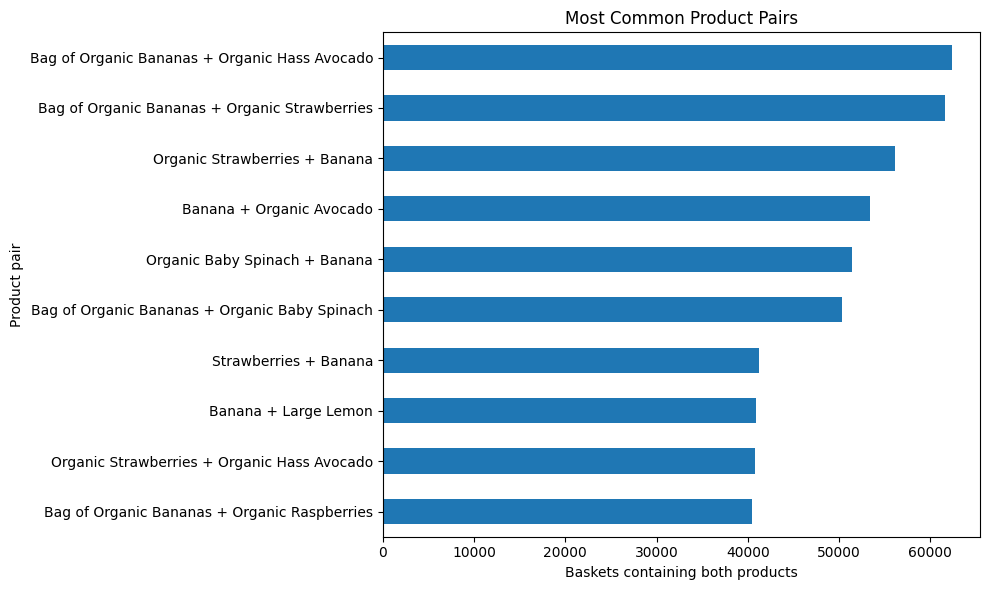

In [54]:
top_pairs = pair_counts.sort_values(
    "orders_together"
).tail(10).copy()

top_pairs["pair_name"] = (
    top_pairs["product_a"] + " + " + top_pairs["product_b"]
)

top_pairs.plot(
    kind="barh",
    x="pair_name",
    y="orders_together",
    legend=False,
    title="Most Common Product Pairs",
    xlabel="Baskets containing both products",
    ylabel="Product pair",
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

Strongest associations

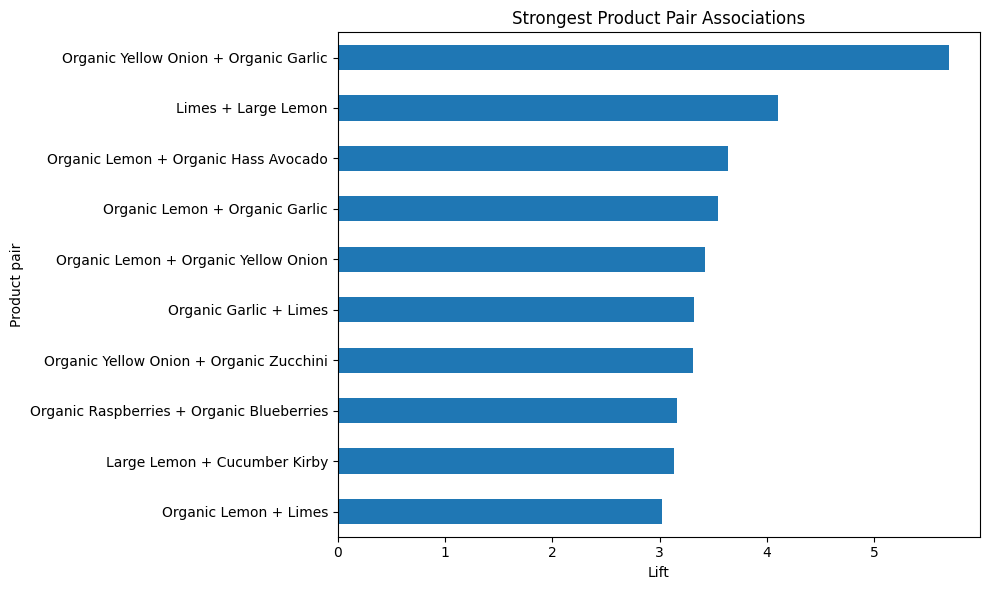

In [55]:
lift_pairs = pair_counts[
    pair_counts["orders_together"] >= 1000
].sort_values("lift").tail(10).copy()

lift_pairs["pair_name"] = (
    lift_pairs["product_a"] + " + " + lift_pairs["product_b"]
)

lift_pairs.plot(
    kind="barh",
    x="pair_name",
    y="lift",
    legend=False,
    title="Strongest Product Pair Associations",
    xlabel="Lift",
    ylabel="Product pair",
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()